In [2]:

import numpy as np
import pandas as pd
from pathlib import Path


rng = np.random.default_rng(42)

out = Path("/content/marketplace_data")
out.mkdir(parents=True, exist_ok=True)

#самозаданные параметры
N_USERS = 20000
N_CAMPAIGNS = 100
N_IMPRESSIONS = 200000

# Начало периода
start = pd.Timestamp("2026-01-01")

print("Библиотеки подключены!")


Библиотеки подключены!


In [3]:

campaigns = pd.DataFrame({
    "campaign_id": np.arange(1, N_CAMPAIGNS + 1),

    "seller_id": rng.integers(
        1, 31, size=N_CAMPAIGNS
    ),

    "category": rng.choice(
        ["Electronics", "Beauty", "Home",
         "Clothing", "Sports"],
        size=N_CAMPAIGNS
    ),

    "start_date": ["2026-01-01"] * N_CAMPAIGNS,

    "end_date": ["2026-03-01"] * N_CAMPAIGNS,

    "daily_budget": rng.integers(
        1000, 10001, size=N_CAMPAIGNS
    )
})

display(campaigns.head())
print("Всего кампаний:", len(campaigns))


,campaign_id,seller_id,category,start_date,end_date,daily_budget
0,1,3,Sports,2026-01-01,2026-03-01,4296
1,2,24,Electronics,2026-01-01,2026-03-01,9178
2,3,20,Sports,2026-01-01,2026-03-01,5456
3,4,14,Electronics,2026-01-01,2026-03-01,7298
4,5,13,Clothing,2026-01-01,2026-03-01,5117


Всего кампаний: 100


In [4]:


users = np.arange(1, N_USERS + 1)

# Случайное разделение на две равные (моё допущение) группы
groups = rng.permutation(
    np.repeat(
        ["control", "treatment"],
        N_USERS // 2
    )
)

experiment_users = pd.DataFrame({
    "user_id": users,
    "experiment_group": groups,
    "exposure_time": ["2026-01-01 00:00:00"] * N_USERS
})

display(experiment_users.head())

print(experiment_users["experiment_group"].value_counts())


,user_id,experiment_group,exposure_time
0,1,treatment,2026-01-01 00:00:00
1,2,treatment,2026-01-01 00:00:00
2,3,control,2026-01-01 00:00:00
3,4,treatment,2026-01-01 00:00:00
4,5,control,2026-01-01 00:00:00


experiment_group
treatment    10000
control      10000
Name: count, dtype: int64


In [5]:

# У каждого пользователя должна быть своя склонность к кликам
user_engagement = rng.beta(
    2, 45, size=N_USERS
)

# У каждой кАмпании своя привлекательность
campaign_multiplier = rng.uniform(
    0.65, 1.5, size=N_CAMPAIGNS
)

# Вероятность заказа после клика
campaign_conv = rng.uniform(
    0.025, 0.10, size=N_CAMPAIGNS
)

# Назначаем показам пользователей и кампании
impression_users = rng.integers(
    1, N_USERS + 1, size=N_IMPRESSIONS
)

impression_campaigns = rng.integers(
    1, N_CAMPAIGNS + 1, size=N_IMPRESSIONS
)

# Случайное время показа в пределах 60 дней
seconds = rng.integers(
    0, 60 * 24 * 60 * 60, size=N_IMPRESSIONS
)

imp_times = start + pd.to_timedelta(
    seconds, unit="s"
)

print("Сгенерировано показов:", len(impression_users))


Сгенерировано показов: 200000


In [6]:

probs = np.clip(
    user_engagement[impression_users - 1]
    * campaign_multiplier[impression_campaigns - 1]
    * np.where(
        groups[impression_users - 1] == "treatment",
        1.12,
        1.0
    ),
    0,
    0.9
)

# Определяем, какие показы привели к клику
is_click = rng.random(N_IMPRESSIONS) < probs
click_indices = np.flatnonzero(is_click)

# Таблица показов
impressions = pd.DataFrame({
    "user_id": impression_users,
    "campaign_id": impression_campaigns,
    "event_time": imp_times,
    "event_type": "impression",
    "ad_cost": 0.0
})

# Таблица кликов
clicks = impressions.iloc[click_indices].copy()

clicks["event_type"] = "click"

clicks["ad_cost"] = rng.uniform(
    5, 30, size=len(clicks)
).round(2)

# Клик происходит через несколько секунд после показа
clicks["event_time"] = (
    clicks["event_time"]
    + pd.to_timedelta(
        rng.integers(1, 60, size=len(clicks)),
        unit="s"
    )
)

print("Показы:", len(impressions))
print("Клики:", len(clicks))


Показы: 200000
Клики: 9713


In [7]:

ad_events = pd.concat(
    [impressions, clicks],
    ignore_index=True
)

# Сортируем по времени
ad_events = ad_events.sort_values(
    "event_time"
).reset_index(drop=True)

# Добавляем уникальные ID
ad_events.insert(
    0, "event_id",
    np.arange(1, len(ad_events) + 1)
)

display(ad_events.head())

print("Всего событий:", len(ad_events))
print(ad_events["event_type"].value_counts())


,event_id,user_id,campaign_id,event_time,event_type,ad_cost
0,1,2617,86,2026-01-01 00:00:00,impression,0.0
1,2,4671,72,2026-01-01 00:00:14,impression,0.0
2,3,10646,44,2026-01-01 00:00:19,impression,0.0
3,4,1933,91,2026-01-01 00:00:24,impression,0.0
4,5,7541,90,2026-01-01 00:01:20,impression,0.0


Всего событий: 209713
event_type
impression    200000
click           9713
Name: count, dtype: int64


In [8]:

# Выбираем клики, которые привели к заказам
converted = (
    rng.random(len(click_indices))
    < campaign_conv[
        impression_campaigns[click_indices] - 1
    ]
)

converted_clicks = (
    clicks.loc[converted]
    .reset_index(drop=True)
)

# Формируем таблицу заказов
orders = pd.DataFrame({
    "order_id": np.arange(
        1, len(converted_clicks) + 1
    ),

    "user_id": converted_clicks["user_id"].to_numpy(),

    "campaign_id": converted_clicks["campaign_id"].to_numpy(),

    "order_time": (
        pd.to_datetime(converted_clicks["event_time"])
        + pd.to_timedelta(
            rng.integers(
                120, 86400, size=len(converted_clicks)
            ),
            unit="s"
        )
    ),

    "revenue": rng.lognormal(
        mean=7.5,
        sigma=0.6,
        size=len(converted_clicks)
    ).round(2),

    "status": rng.choice(
        ["completed", "cancelled"],
        size=len(converted_clicks),
        p=[0.9, 0.1]
    )
})

display(orders.head())
print("Всего заказов:", len(orders))


,order_id,user_id,campaign_id,order_time,revenue,status
0,1,9144,80,2026-02-18 04:00:10,2667.95,completed
1,2,17968,80,2026-01-10 09:00:10,1681.86,completed
2,3,8350,38,2026-02-11 10:43:04,893.11,completed
3,4,19426,38,2026-01-21 09:18:25,4146.91,completed
4,5,9616,44,2026-01-27 12:03:40,3274.54,completed


Всего заказов: 610


In [9]:

tables = {
    "campaigns": campaigns,
    "ad_events": ad_events,
    "orders": orders,
    "experiment_users": experiment_users
}

for name, df in tables.items():
    path = out / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"{name}: {len(df)} строк -> {path}")



campaigns: 100 строк -> /content/marketplace_data/campaigns.csv
ad_events: 209713 строк -> /content/marketplace_data/ad_events.csv
orders: 610 строк -> /content/marketplace_data/orders.csv
experiment_users: 20000 строк -> /content/marketplace_data/experiment_users.csv


In [10]:
for name, df in tables.items():
    print(f"\n===== {name.upper()} =====")
    display(df.head())
    df.info()



===== CAMPAIGNS =====


,campaign_id,seller_id,category,start_date,end_date,daily_budget
0,1,3,Sports,2026-01-01,2026-03-01,4296
1,2,24,Electronics,2026-01-01,2026-03-01,9178
2,3,20,Sports,2026-01-01,2026-03-01,5456
3,4,14,Electronics,2026-01-01,2026-03-01,7298
4,5,13,Clothing,2026-01-01,2026-03-01,5117


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   campaign_id   100 non-null    int64 
 1   seller_id     100 non-null    int64 
 2   category      100 non-null    object
 3   start_date    100 non-null    object
 4   end_date      100 non-null    object
 5   daily_budget  100 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 4.8+ KB

===== AD_EVENTS =====


,event_id,user_id,campaign_id,event_time,event_type,ad_cost
0,1,2617,86,2026-01-01 00:00:00,impression,0.0
1,2,4671,72,2026-01-01 00:00:14,impression,0.0
2,3,10646,44,2026-01-01 00:00:19,impression,0.0
3,4,1933,91,2026-01-01 00:00:24,impression,0.0
4,5,7541,90,2026-01-01 00:01:20,impression,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209713 entries, 0 to 209712
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   event_id     209713 non-null  int64         
 1   user_id      209713 non-null  int64         
 2   campaign_id  209713 non-null  int64         
 3   event_time   209713 non-null  datetime64[ns]
 4   event_type   209713 non-null  object        
 5   ad_cost      209713 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 9.6+ MB

===== ORDERS =====


,order_id,user_id,campaign_id,order_time,revenue,status
0,1,9144,80,2026-02-18 04:00:10,2667.95,completed
1,2,17968,80,2026-01-10 09:00:10,1681.86,completed
2,3,8350,38,2026-02-11 10:43:04,893.11,completed
3,4,19426,38,2026-01-21 09:18:25,4146.91,completed
4,5,9616,44,2026-01-27 12:03:40,3274.54,completed


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 610 entries, 0 to 609
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     610 non-null    int64         
 1   user_id      610 non-null    int64         
 2   campaign_id  610 non-null    int64         
 3   order_time   610 non-null    datetime64[ns]
 4   revenue      610 non-null    float64       
 5   status       610 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 28.7+ KB

===== EXPERIMENT_USERS =====


,user_id,experiment_group,exposure_time
0,1,treatment,2026-01-01 00:00:00
1,2,treatment,2026-01-01 00:00:00
2,3,control,2026-01-01 00:00:00
3,4,treatment,2026-01-01 00:00:00
4,5,control,2026-01-01 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   user_id           20000 non-null  int64 
 1   experiment_group  20000 non-null  object
 2   exposure_time     20000 non-null  object
dtypes: int64(1), object(2)
memory usage: 468.9+ KB


In [11]:

events_with_category = ad_events.merge(
    campaigns[["campaign_id", "category"]],
    on="campaign_id",
    how="left"
)

category_metrics = (
    events_with_category
    .groupby(["category", "event_type"])
    .size()
    .unstack(fill_value=0)
)

category_metrics["CTR"] = (
    category_metrics["click"]
    / category_metrics["impression"]
    * 100
)

display(category_metrics.sort_values("CTR", ascending=False))


event_type,click,impression,CTR
category,,,
Electronics,2095,40032,5.233313
Home,2429,50155,4.842987
Sports,1427,29880,4.775770
Beauty,1613,34043,4.738125
Clothing,2149,45890,4.682937


In [13]:
import matplotlib.pyplot as plt

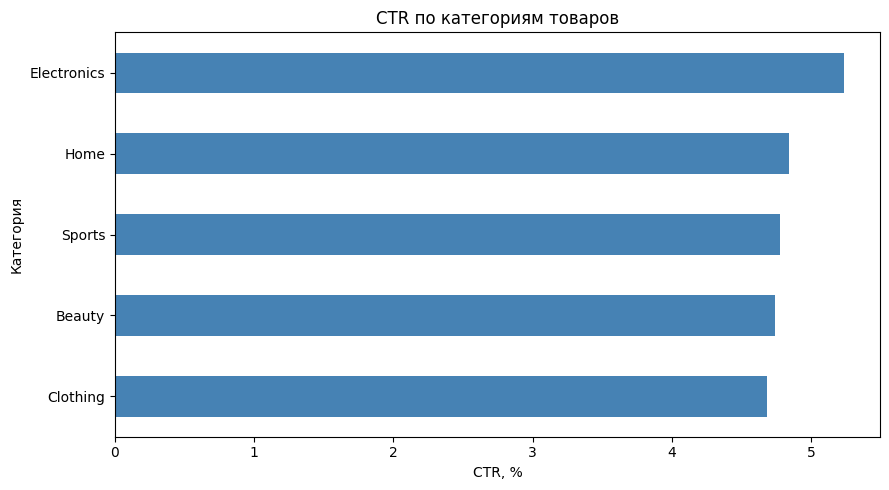

In [14]:
category_metrics["CTR"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("CTR по категориям товаров")
plt.xlabel("CTR, %")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()

**Первичный анализ CTR по категориям**

**Цель**: сравнить кликабельность - как работает реклама между нашими пятью категориями товаров

**Результат**: продукты из категории "электроника" показалаи самый высокий CTR.

**Вывод**: различия CTR показывают, насколько часто пользователи кликают по объявлениям разных категорий. Однако для оценки экономической эффективности необходимо дополнительно проанализировать расходы и заказы, а также другие метрики эффективности кампаний.

In [24]:

# Считаем показы и клики по каждой кампании
campaign_events = (
    ad_events.groupby(["campaign_id", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Считаем расходы на рекламу
spend = (
    ad_events.groupby("campaign_id")["ad_cost"]
    .sum()
    .reset_index(name="ad_spend")
)

# Считаем завершённые заказы и выручку
sales = (
    orders[orders["status"] == "completed"]
    .groupby("campaign_id")
    .agg(
        orders_count=("order_id", "count"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

# Объединяем данные
metrics = (
    campaigns[["campaign_id", "category"]]
    .merge(campaign_events, on="campaign_id", how="left")
    .merge(spend, on="campaign_id", how="left")
    .merge(sales, on="campaign_id", how="left")
)

# Заполняем отсутствующие значения нулями
columns = [
    "impression", "click", "ad_spend",
    "orders_count", "revenue"
]

metrics[columns] = metrics[columns].fillna(0)

# Рассчитываем показатели
metrics["CTR"] = (
    metrics["click"] / metrics["impression"] * 100
)

metrics["CPC"] = (
    metrics["ad_spend"] /
    metrics["click"].replace(0, np.nan)
)

metrics["CVR"] = (
    metrics["orders_count"] /
    metrics["click"].replace(0, np.nan) * 100
)

metrics["ROAS"] = (
    metrics["revenue"] /
    metrics["ad_spend"].replace(0, np.nan)
)

display(metrics.head())


,campaign_id,category,click,impression,ad_spend,orders_count,revenue,CTR,CPC,CVR,ROAS
0,1,Sports,109,2056,1975.88,7.0,15648.42,5.301556,18.127339,6.422018,7.919722
1,2,Electronics,124,1991,2114.67,3.0,8067.90,6.228026,17.053790,2.419355,3.815205
2,3,Sports,102,2007,1686.90,8.0,17707.56,5.082212,16.538235,7.843137,10.497101
3,4,Electronics,69,1982,1140.56,8.0,16550.50,3.481332,16.529855,11.594203,14.510854
4,5,Clothing,107,2014,1868.44,6.0,14928.24,5.312810,17.462056,5.607477,7.989681


CTR — Click-Through Rate - какая доля рекламных показов привела к клику

CPC — Cost Per Click - сколько в среднем рекламодатель платит за один клик по рекламе

CVR — Conversion Rate - какая доля рекламных кликов привела к заказам

ROAS — Return on Ad Spend - сколько рублей рекламной выручки приходится на каждый рубль рекламных расходов



In [18]:

# Исключаем кампании без расходов
valid_metrics = metrics[metrics["ad_spend"] > 0]

# 10 кампаний с самым низким ROAS
worst_campaigns = valid_metrics.sort_values(
    "ROAS", ascending=True
).head(10)

display(
    worst_campaigns[
        ["campaign_id", "category", "CTR",
         "CPC", "CVR", "ROAS", "ad_spend"]
    ].round(2)
)


,campaign_id,category,CTR,CPC,CVR,ROAS,ad_spend
16,17,Electronics,4.28,17.67,0.00,0.00,1502.21
92,93,Clothing,3.12,16.20,0.00,0.00,1004.22
6,7,Clothing,3.30,17.65,1.54,0.69,1147.27
88,89,Beauty,5.97,17.83,1.69,1.15,2104.18
66,67,Beauty,5.72,17.77,0.88,1.56,2007.52
28,29,Home,4.79,17.65,1.03,1.58,1712.02
78,79,Sports,4.97,18.59,2.04,1.61,1821.77
59,60,Clothing,4.86,18.86,2.00,1.95,1885.74
20,21,Home,3.30,16.80,2.99,2.19,1125.61
99,100,Sports,5.89,17.24,1.75,2.30,1964.82


In [20]:
median_ctr = metrics["CTR"].median()
median_roas = metrics["ROAS"].median()

print("Медианный CTR:", median_ctr)
print("Медианный ROAS:", median_roas)

# Кампании с высоким CTR и низким ROAS
problem_campaigns = metrics[
    (metrics["CTR"] > median_ctr) &
    (metrics["ROAS"] < median_roas)
]

print("Количество кампаний:", len(problem_campaigns))

Медианный CTR: 4.814701192448467
Медианный ROAS: 6.4057254427050685
Количество кампаний: 25


In [27]:

# Рекламные расходы
python_spend = ad_events["ad_cost"].sum()

# Завершённые заказы
completed_orders = orders[
    orders["status"] == "completed"
]

python_revenue = completed_orders["revenue"].sum()

print("Расходы:", python_spend)
print("Выручка:", python_revenue)
print("Завершённые заказы:", len(completed_orders))


Расходы: 170949.96
Выручка: 1216483.33
Завершённые заказы: 543


In [29]:

print(
    ad_events.groupby("event_type")
    .agg(
        event_count=("event_type", "size"),
        total_spend=("ad_cost", "sum")
    )
)


            event_count  total_spend
event_type                          
click              9713    170949.96
impression       200000         0.00


In [32]:

display(
    ad_events[ad_events["event_type"] == "click"]
    [["event_id", "campaign_id", "user_id", "ad_cost"]]
    .sort_values("event_id")
    .head(10)
)


,event_id,campaign_id,user_id,ad_cost
11,12,28,12514,26.22
31,32,77,2540,8.43
61,62,40,12937,7.99
67,68,35,1153,27.08
68,69,43,7010,5.91
82,83,58,15245,11.39
102,103,95,3543,18.68
174,175,37,8876,10.90
221,222,65,18141,14.24
234,235,34,19682,14.70


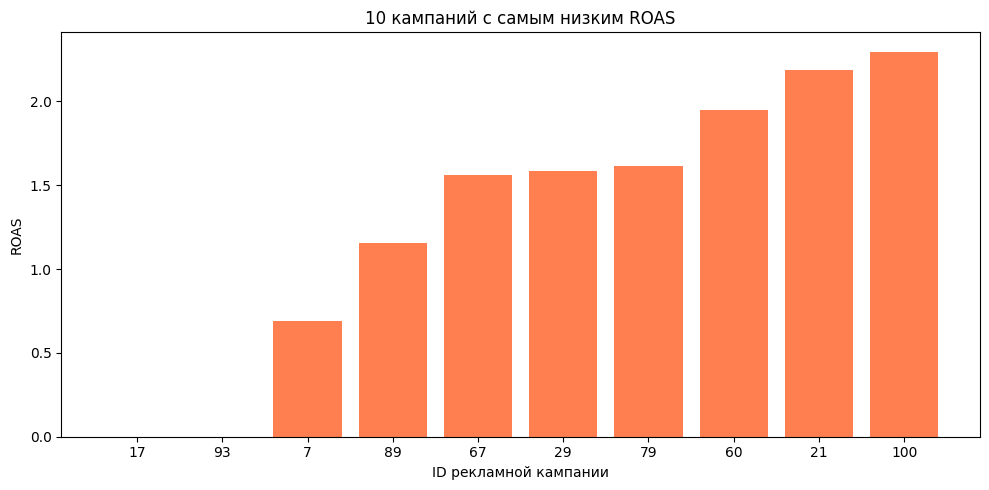

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    worst_campaigns["campaign_id"].astype(str),
    worst_campaigns["ROAS"],
    color="coral"
)

plt.title("10 кампаний с самым низким ROAS")
plt.xlabel("ID рекламной кампании")
plt.ylabel("ROAS")
plt.tight_layout()
plt.show()


Во - первых видим, что не всегда высокий CTR = хорошая кампания, по другим метрикам видно, что даже с выскоим CTR есть кампании, которые находтся в выборке самых неуспешных по метрике ROAS, которая показывает, как соотносится рекламный бюджет и выручка от рекламы. Зато видно, что дркгие показатели такие как конверсия, тоже наглядно показывают, какие товары проседают по продажам - и даже если на карточку товара кликают, то до целевого действия "покупки" человек не доходит (конверсия смотрим как отношения покупателей к пользователям).

In [34]:
import pandas as pd

csv_events = pd.read_csv(
    "/content/marketplace_data/ad_events.csv"
)

print("Расходы в CSV:", round(csv_events["ad_cost"].sum(), 2))
print("Расходы в Python:", round(ad_events["ad_cost"].sum(), 2))

Расходы в CSV: 170949.96
Расходы в Python: 170949.96


In [35]:
from google.colab import files

files.download("/content/marketplace_data/ad_events.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>